In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import numpy as np
import seaborn as sns

# installs Sentence Transformers which gives us a pretrained MiniLM encoder
%pip install sentence-transformers
from sentence_transformers import SentenceTransformer
from sklearn import model_selection, linear_model, metrics

In [ ]:
url = "https://raw.githubusercontent.com/retieedra/CS156/main/assignments/01-first-pipeline/predicting-poll-scores/data/"

df = pd.read_csv(url + "graded_polls.csv")
df2 = pd.read_csv(url + "minerva_graded_polls_student_2.csv")

df2 = df2.rename(columns={
    "Poll record ID": "response_id",
    "Class": "course",
    "Poll question": "question",
    "Answer": "response",
    "Score": "score",
    "Session number": "session_number",
    "Grading tag": "grading_tag"
})

df = pd.concat([df, df2[df.columns]], ignore_index=True)
df.head()

,response_id,course,question,response,score,session_number,grading_tag
0,99557-poll-3-grade-1-1,CS110,One of your friends claims to have done an exp...,"No, this code is not done correctly, nor are t...",3,4,#ClassParticipation
1,99559-poll-3-grade-1-1,CS110,"In today's activities, we saw how navigating a...","It came down to analyzing the algorithm, for e...",3,5,#ClassParticipation
2,99565-poll-3-grade-1-1,CS110,What are **two important reasons** for using r...,"Firstly, as Ahmed said, randomization enables ...",4,8,#ClassParticipation
3,99567-poll-1-grade-1-1,CS110,Compare **deterministic quicksort** with **mer...,similarities:\n- both divide and conquer\n- us...,3,9,#ClassParticipation
4,99573-poll-2-grade-1-1,CS110,We have discussed a computational solution for...,We can basically use two heaps to make the cal...,3,12,#ClassParticipation


In [ ]:
# count the responses for each score
score_counts = df["score"].value_counts()

# count the responses for each score and put them in order
score_counts = df["score"].value_counts().sort_index()

print(score_counts)

# put the course, question and response together for minilm
df["text"] = "course: " + df["course"] + "\nquestion: " + df["question"] + "\nresponse: " + df["response"]

score
2     61
3    124
4     75
Name: count, dtype: int64


In [ ]:
model = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2")

# turn each text into 384 numbers without training minilm
X = model.encode(df["text"].tolist(), normalize_embeddings=True)

# keep the scores separate as the labels
y = df["score"].to_numpy()

# if all responses are successful prints (260, 384) which is the shape of the data
X.shape

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

(260, 384)

In [ ]:
# keep similar score proportions across five folds
kfold = model_selection.StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

splits = []

for training, test in kfold.split(X, y):
    # reserve validation data within the training portion
    train, validation = model_selection.train_test_split(
        training,
        test_size=0.2,
        stratify=y[training],
        random_state=42
    )

    # every model will use these same row numbers
    splits.append((train, validation, test))

In [ ]:
# show precision, recall and f1 for each score
def evaluate_model(actual, predictions, name):
    print(name)
    print(metrics.classification_report(
        actual, predictions, labels=[2, 3, 4], zero_division=0
    ))
    return {
        "model": name,
        "accuracy": metrics.accuracy_score(actual, predictions)
    }

In [ ]:
# model 1: logistic regression

actual_scores = []
baseline_predictions = []
linear_predictions = []

for train, validation, test in splits:
    x_train = X[train]
    y_train = y[train]
    x_test = X[test]
    y_test = y[test]

    # the baseline predicts the most common training score
    majority_score = pd.Series(y_train).mode()[0]
    baseline_predictions.extend([majority_score] * len(y_test))

    linear_clf = linear_model.LogisticRegression()
    linear_clf.fit(x_train, y_train)

    linear_preds = linear_clf.predict(x_test)

    # collect predictions from the held-out folds
    linear_predictions.extend(linear_preds)
    actual_scores.extend(y_test)

In [ ]:
# use the same network structure for both neural models, with param for dropout
def create_ffn(dropout):
    model = tf.keras.Sequential([
        tf.keras.Input(shape=(384,)),
        tf.keras.layers.Dense(8, activation="sigmoid"),
        tf.keras.layers.Dropout(dropout),
        tf.keras.layers.Dense(3)
    ])

    model.compile(
        optimizer=tf.keras.optimizers.SGD(learning_rate=0.01),
        # the three outputs are raw logits
        loss=tf.keras.losses.SparseCategoricalCrossentropy(
            from_logits=True
        )
    )

    return model

In [ ]:
# models 2 and 3: ffn without and with dropout

ffn_predictions = []
dropout_predictions = []

ffn_histories = []
dropout_histories = []

for train, validation, test in splits:
    # start each fold with a fresh model
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(42)

    x_train = X[train]
    x_val = X[validation]
    x_test = X[test]

    # convert scores 2, 3 and 4 into labels 0, 1 and 2
    y_train = y[train] - 2
    y_val = y[validation] - 2

    ffn = create_ffn(0)
    # here we set the dropout rate
    ffn_dropout = create_ffn(0.2)

    # match the starting weights
    ffn_dropout.set_weights(ffn.get_weights())

    # train model 2 for exactly 20 epochs
    history = ffn.fit(
        x_train,
        y_train,
        validation_data=(x_val, y_val),
        epochs=20,
        batch_size=32,
        shuffle=False,
        verbose=0)

    ffn_histories.append(history.history)

    # choose the largest output and convert back to the original scores
    outputs = ffn.predict(x_test, verbose=0)
    predictions = outputs.argmax(axis=1) + 2
    ffn_predictions.extend(predictions)

    # train model 3 with the same settings and batch order
    history = ffn_dropout.fit(
        x_train,
        y_train,
        validation_data=(x_val, y_val),
        epochs=20,
        batch_size=32,
        shuffle=False,
        verbose=0)

    dropout_histories.append(history.history)

    outputs = ffn_dropout.predict(x_test, verbose=0)
    predictions = outputs.argmax(axis=1) + 2
    dropout_predictions.extend(predictions)

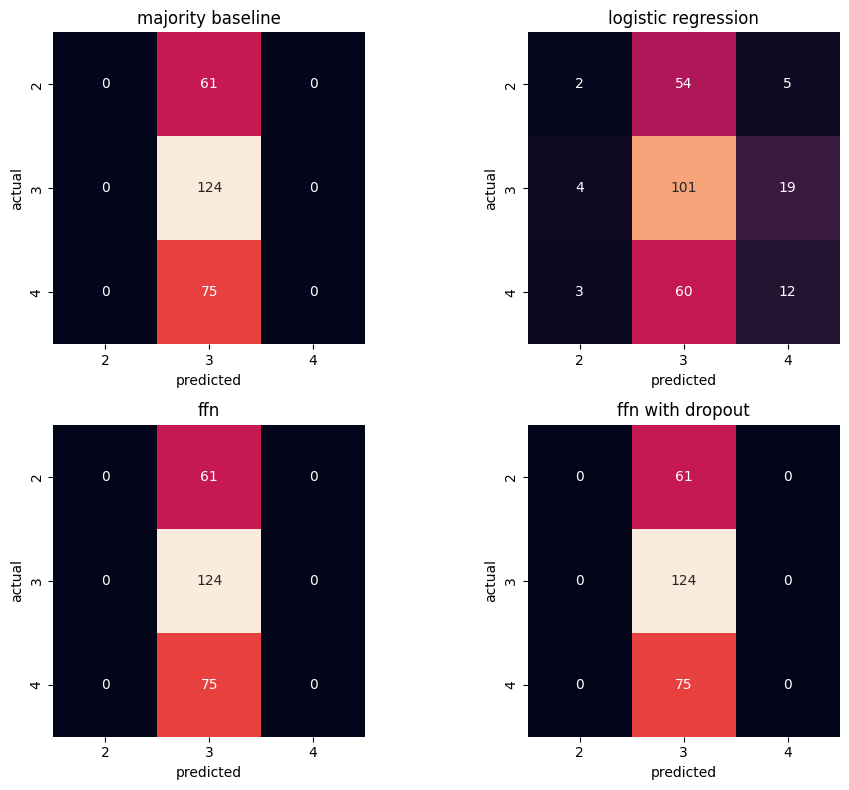

In [ ]:
model_predictions = [
    ("majority baseline", baseline_predictions),
    ("logistic regression", linear_predictions),
    ("ffn", ffn_predictions),
    ("ffn with dropout", dropout_predictions)
]

fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(10, 8))

# use the same colour scale for all four matrices
largest_class = pd.Series(actual_scores).value_counts().max()

for ax, (name, predictions) in zip(axes.flat, model_predictions):
    confusion_mat = metrics.confusion_matrix(
        actual_scores,
        predictions,
        labels=[2, 3, 4]
    )

    sns.heatmap(
        confusion_mat,
        square=True,
        annot=True,
        fmt="d",
        cbar=False,
        vmin=0,
        vmax=largest_class,
        xticklabels=[2, 3, 4],
        yticklabels=[2, 3, 4],
        ax=ax
    )

    ax.set_xlabel("predicted")
    ax.set_ylabel("actual")
    ax.set_title(name)

plt.tight_layout()
plt.show()

In [ ]:
results = []

# evaluate every model using the same function
for name, predictions in model_predictions:
    result = evaluate_model(actual_scores, predictions, name)
    results.append(result)

comparison = pd.DataFrame(results)

print("model comparison")
print(comparison.round(3))

majority baseline
              precision    recall  f1-score   support

           2       0.00      0.00      0.00        61
           3       0.48      1.00      0.65       124
           4       0.00      0.00      0.00        75

    accuracy                           0.48       260
   macro avg       0.16      0.33      0.22       260
weighted avg       0.23      0.48      0.31       260

logistic regression
              precision    recall  f1-score   support

           2       0.22      0.03      0.06        61
           3       0.47      0.81      0.60       124
           4       0.33      0.16      0.22        75

    accuracy                           0.44       260
   macro avg       0.34      0.34      0.29       260
weighted avg       0.37      0.44      0.36       260

ffn
              precision    recall  f1-score   support

           2       0.00      0.00      0.00        61
           3       0.48      1.00      0.65       124
           4       0.00      0.00

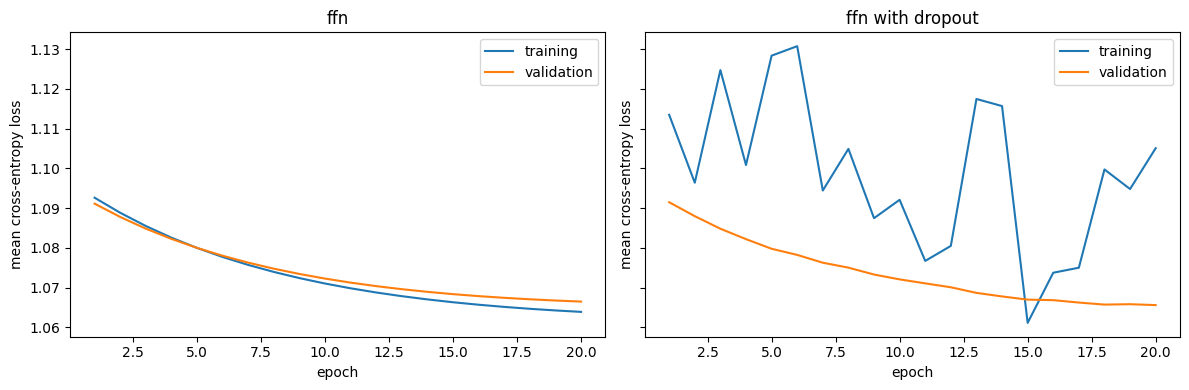

In [ ]:
# average each epoch's loss across the folds
ffn_train_loss = np.mean(
    [history["loss"] for history in ffn_histories],
    axis=0
)

ffn_val_loss = np.mean(
    [history["val_loss"] for history in ffn_histories],
    axis=0
)

dropout_train_loss = np.mean(
    [history["loss"] for history in dropout_histories],
    axis=0
)

dropout_val_loss = np.mean(
    [history["val_loss"] for history in dropout_histories],
    axis=0
)

epochs = range(1, 21)

fig, axes = plt.subplots(
    ncols=2,
    figsize=(12, 4),
    sharex=True,
    sharey=True
)

axes[0].plot(epochs, ffn_train_loss, label="training")
axes[0].plot(epochs, ffn_val_loss, label="validation")
axes[0].set_title("ffn")

axes[1].plot(epochs, dropout_train_loss, label="training")
axes[1].plot(epochs, dropout_val_loss, label="validation")
axes[1].set_title("ffn with dropout")

for ax in axes:
    ax.set_xlabel("epoch")
    ax.set_ylabel("mean cross-entropy loss")
    ax.legend()

plt.tight_layout()
plt.show()